In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import warnings
from sklearn.svm import SVC

In [5]:
!pip install openpyxl
df = pd.read_excel("/content/ai4i2020.xlsx")

In [6]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [10]:
X = df[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]

In [11]:
y=df["Machine failure"]
print("Input shape:",X.shape)
print("Output shape",y.shape)


Input shape: (10000, 6)
Output shape (10000,)


In [13]:
from pandas.core.arrays import categorical
categorical_features =["Type"]
numerical_features=[
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 8000
Testing samples: 2000


In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numerical_features)
    ]
)

In [17]:
linear_svm = Pipeline (steps=[("preprocessor", preprocessor), ("classifier", SVC(kernel="linear"))])
linear_svm.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type']),
                                                 ('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]'])])),
                ('classifier', SVC(kernel='linear'))])

In [19]:
y_pred_linear = linear_svm.predict(X_test)

In [20]:
accuracy_linear = accuracy_score (y_test,y_pred_linear)
precission_linear = precision_score(y_test, y_pred_linear)
recall_linear=recall_score (y_test,y_pred_linear)
f1_linear=f1_score(y_test,y_pred_linear)
print("Accuracy:", accuracy_linear)
print("Precision:", precission_linear)
print("Recall:", recall_linear)
print("F1 Score:", f1_linear)

Accuracy: 0.9695
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [21]:
print(classification_report(y_test,y_pred_linear, target_names=["No Failure", "Failure"], zero_division=0))

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1939
     Failure       0.00      0.00      0.00        61

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.94      0.97      0.95      2000



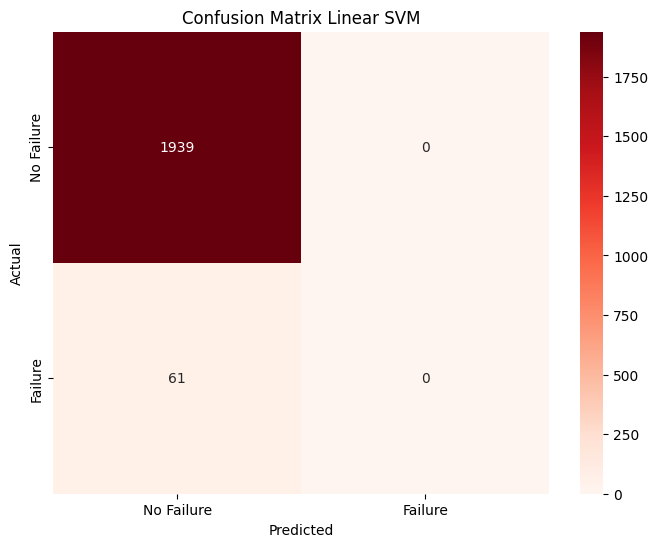

In [23]:
cm_linear=confusion_matrix(y_test,y_pred_linear)
plt.figure(figsize=(8,6))
sns.heatmap(cm_linear, annot=True, fmt="d", cmap="Reds", xticklabels=["No Failure", "Failure"], yticklabels=["No Failure", "Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Linear SVM")
plt.show()

In [24]:
rbf_svm=Pipeline (steps=[("preprocessor", preprocessor), ("classifier", SVC (kernel="rbf"))])
rbf_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type']),
                                                 ('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]'])])),
                ('classifier', SVC())])

In [25]:
y_pred_rbf = rbf_svm.predict(X_test)

In [26]:
accuracy_rbf = accuracy_score (y_test, y_pred_rbf)
precission_rbf=precision_score(y_test,y_pred_rbf)
recall_rbf = recall_score(y_test, y_pred_rbf)
f1_rbf = f1_score(y_test,y_pred_rbf)
print("Accuracy:", accuracy_rbf)
print("Precision:", precission_rbf)
print("Recall:", recall_rbf)
print("F1 Score:", f1_rbf)

Accuracy: 0.977
Precision: 0.8571428571428571
Recall: 0.29508196721311475
F1 Score: 0.43902439024390244


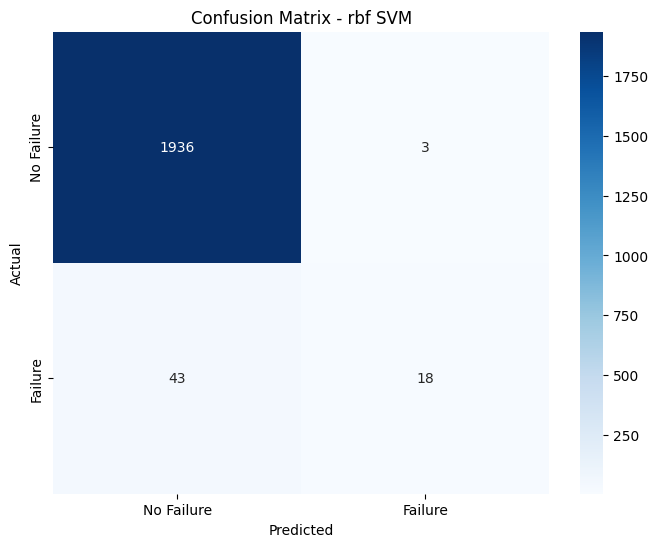

In [27]:
cm_rbf = confusion_matrix(y_test, y_pred_rbf)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_rbf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - rbf SVM")
plt.show()
